# AIMLCZG523 - Machine Learning Operations (MLOps)
## Assignment 01: Exploratory Data Analysis (EDA)
**BITS ID:** 2025AF05099  
**Dataset:** UCI Heart Disease (Cleveland Clinic Foundation)  

### Objective:
Analyze clinical attributes associated with the presence or absence of heart disease, handle missing data, examine distributions, and prepare features for model engineering.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")

### 1. Load Cleaned Dataset

In [2]:
DATA_PATH = "../data/processed/heart_disease_cleaned.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


### 2. Statistical Summary & Missing Values

In [3]:
print("Missing Values per Column:")
print(df.isnull().sum())
df.describe().T

Missing Values per Column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### 3. Target Class Balance Analysis

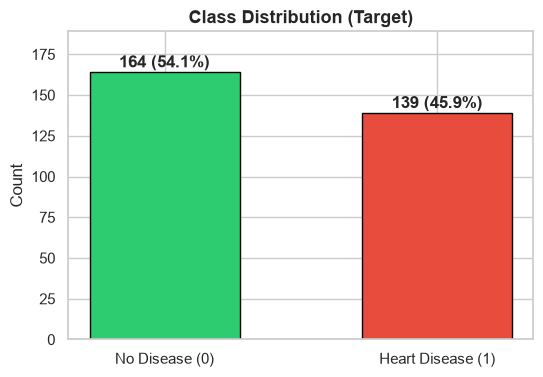

In [4]:
plt.figure(figsize=(6, 4))
counts = df["target"].value_counts().sort_index()
bars = plt.bar(["No Disease (0)", "Heart Disease (1)"], counts.values, color=["#2ecc71", "#e74c3c"], edgecolor="black", width=0.55)
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 3, f"{h} ({h/len(df)*100:.1f}%)", ha='center', fontweight='bold')
plt.title("Class Distribution (Target)", fontsize=13, fontweight='bold')
plt.ylabel("Count")
plt.ylim(0, max(counts.values) + 25)
plt.show()

### 4. Correlation Matrix

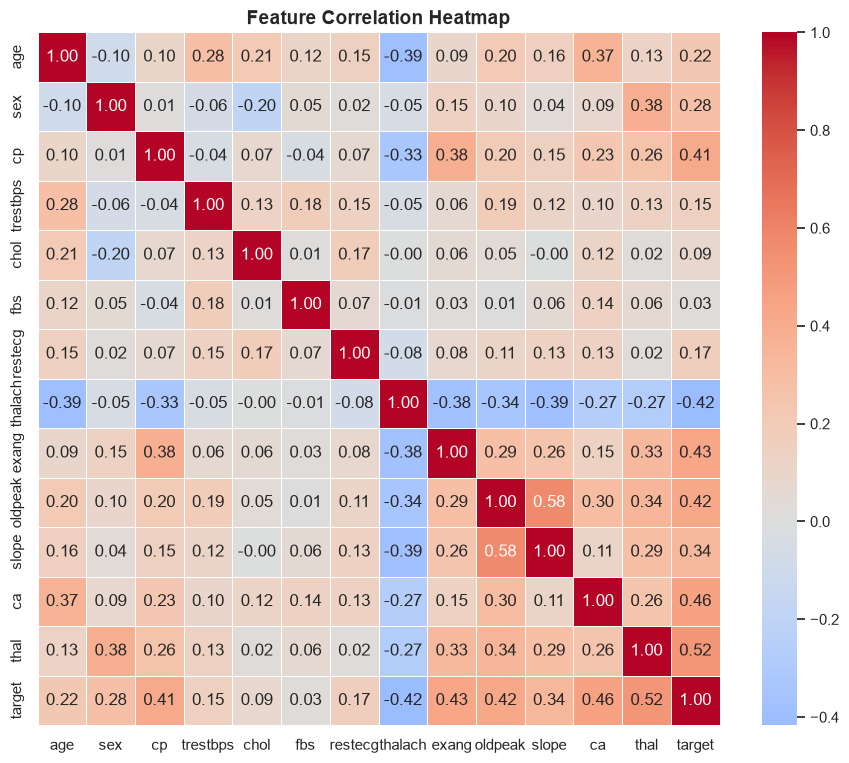

In [5]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Feature Correlation Heatmap", fontsize=14, fontweight='bold')
plt.show()

### 5. Key Clinical Findings:
- **Target Balance:** 54.1% patients have no heart disease, 45.9% have confirmed heart disease, making this a balanced classification problem without requiring severe resampling.
- **Strongest Positive Predictors:** `thal` (defect type, r=0.52), `ca` (major vessels, r=0.46), `exang` (exercise-induced angina, r=0.43), `oldpeak` (ST depression, r=0.42), and `cp` (chest pain type, r=0.41).
- **Strongest Negative Predictor:** `thalach` (maximum heart rate, r=-0.42), indicating patients with heart disease have significantly lower maximum heart rate capacity.